# Chart-to-Table Extraction with Weak QA Supervision
### IE 643 Course Project — Team NeuroFusion (Jaydip 22b4221, Disham 22b4211)

This notebook trains **two different decoder architectures** (T5 and BART) on top of a shared,
**frozen, document-pretrained Pix2Struct vision encoder**, to reconstruct a chart's underlying
data table using only **(chart, question, answer)** supervision — the ground-truth table is
loaded only at evaluation time, never during training.

**What this notebook produces (saved under `/kaggle/working/experiments/`):**
- Per-architecture training logs (loss per epoch, as CSV + PNG plot)
- Per-architecture parameter counts (trainable vs. frozen)
- Qualitative generated tables at several epochs (proof of what the model actually produced)
- A final comparison table across architectures (cell accuracy, split into *mined* vs. *never-mined*
  cells, plus relaxed QA accuracy)
- `experiment_report.json` — a single consolidated file you can quote numbers from directly in your report
- An inference cell: give it any new chart image, get back a predicted table

> **Honesty note on scope.** The project proposal described a fully differentiable program executor
> that back-propagates an answer's loss into individual table cells. That is open research-level
> engineering. What this notebook actually implements is a **rule-based weak-supervision miner**:
> it extracts `(category, value)` pairs directly from question/answer text (never from the table
> file) to build a per-chart pseudo-table as the decoder's training target. This keeps the core
> constraint intact (no table access during training) while being something that reliably runs to
> completion. The gap between the two is reported explicitly in Step 7, which is itself a legitimate
> experimental finding to present.

## Step 0 — Install / import / config

In [1]:
# Kaggle images sometimes ship an older transformers version without full Pix2Struct support.
!pip install -q -U "transformers>=4.38" sentencepiece 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
from transformers import Pix2StructForConditionalGeneration

In [3]:
import os, re, json, glob, random, math, time, textwrap
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import (
    Pix2StructVisionModel, Pix2StructProcessor,
    T5ForConditionalGeneration, AutoTokenizer,
    BartForConditionalGeneration,
)
from transformers.modeling_outputs import BaseModelOutput

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

CONFIG = {
    # ---- data ----
    "n_train": 6400,          # subsample size requested (out of ~18k+ available)
    "n_val":   750,
    "n_test":  1600,
    # ---- encoder ----
    "encoder_name": "google/pix2struct-base",   # document-pretrained, NOT chart-finetuned
    "max_patches": 512,                          # lower = faster/less memory on a T4
    # ---- decoders ----
    "t5_name":   "t5-small",
    "bart_name": "facebook/bart-base",
    "max_target_len": 256,
    # ---- training ----
    "batch_size": 4,
    "epochs": 30,
    "lr": 3e-4,
    "weight_decay": 0.01,
    "grad_clip": 1.0,
    "num_workers": 2,
    # ---- output ----
    "out_dir": "/kaggle/working/experiments",
}
os.makedirs(CONFIG["out_dir"], exist_ok=True)
print(json.dumps(CONFIG, indent=2))

Device: cuda
{
  "n_train": 6400,
  "n_val": 750,
  "n_test": 1600,
  "encoder_name": "google/pix2struct-base",
  "max_patches": 512,
  "t5_name": "t5-small",
  "bart_name": "facebook/bart-base",
  "max_target_len": 256,
  "batch_size": 4,
  "epochs": 30,
  "lr": 0.0003,
  "weight_decay": 0.01,
  "grad_clip": 1.0,
  "num_workers": 2,
  "out_dir": "/kaggle/working/experiments"
}


## Step 0b — Inspect your dataset (run this and read the printed output first!)

This cell does **not** assume a fixed folder layout. It searches everything under `/kaggle/input`
for ChartQA-style JSON annotation files and chart PNGs, and prints what it finds, plus one sample
record, so you can confirm (or fix) the key names used later in `load_split()`.

In [4]:
INPUT_ROOT = "/kaggle/input"

def tree_preview(root, max_entries=60):
    count = 0
    for dirpath, dirnames, filenames in os.walk(root):
        depth = dirpath[len(root):].count(os.sep)
        if depth > 3:
            dirnames[:] = []
            continue
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath) or dirpath}/")
        for f in filenames[:5]:
            print(f"{indent}  {f}")
            count += 1
            if count > max_entries:
                return
        if len(filenames) > 5:
            print(f"{indent}  ... ({len(filenames)} files total)")

print("=== Directory preview under /kaggle/input ===")
tree_preview(INPUT_ROOT)

print()
print("=== JSON annotation files found ===")
json_files = glob.glob(f"{INPUT_ROOT}/**/*.json", recursive=True)
for f in json_files[:20]:
    print(f)
print(f"... {len(json_files)} json files total")

if json_files:
    sample = json_files[0]
    with open(sample) as f:
        data = json.load(f)
    print()
    print(f"=== Sample content of {sample} ===")
    print(json.dumps(data[:2] if isinstance(data, list) else data, indent=2)[:1500])

print()
print("=== PNG chart images found ===")
png_files = glob.glob(f"{INPUT_ROOT}/**/*.png", recursive=True)
print(f"{len(png_files)} png files, e.g.:")
for f in png_files[:5]:
    print(f)

print()
print("=== Table (CSV) files found ===")
csv_files = [f for f in glob.glob(f"{INPUT_ROOT}/**/*.csv", recursive=True)]
print(f"{len(csv_files)} csv files, e.g.:")
for f in csv_files[:5]:
    print(f)

=== Directory preview under /kaggle/input ===
input/
  datasets/
    harshk1111/
      chartqa-dataset/

=== JSON annotation files found ===
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_augmented.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_human.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/train_augmented.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/train_human.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/val_augmented.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/val_human.json
... 6 json files total

=== Sample content of /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_augmented.json ===
[
  {
    "imgname": "multi_col_803.png",
    "query": "How many stores did Saint Laurent operate in Western Europe in 2020?",
    "label": "47"
  },
  {
    "imgname": "multi_col_2043

In [5]:
# If the printed structure above does NOT match ChartQA's usual layout
# (a json list of {"imgname"/"image_index": ..., "query"/"question": ..., "label"/"answer": ...}
#  plus a sibling png/ folder and tables/ folder with one csv per chart),
# edit KEY_ALIASES and the path-building logic in `load_split()` below accordingly.

KEY_ALIASES = {
    "image": ["imgname", "image_index", "image", "img_name", "filename"],
    "question": ["query", "question", "Question"],
    "answer": ["label", "answer", "Answer"],
}

def first_present(d, aliases):
    for k in aliases:
        if k in d:
            return d[k]
    return None

## Step 0c — Build a flat index of (image, question, answer, source, split, table_path)

In [6]:
def find_split_jsons():
    """Return a dict: split -> list of (json_path, source_tag) for train/val/test,
    matching *_human.json and *_augmented.json style names anywhere under /kaggle/input."""
    found = {"train": [], "val": [], "test": []}
    for jf in json_files:
        name = os.path.basename(jf).lower()
        split = None
        for cand in ["train", "val", "test"]:
            if cand in jf.lower():
                split = cand
                break
        if split is None:
            continue
        source = "human" if "human" in name else ("augmented" if ("augment" in name or "machine" in name) else "unknown")
        found[split].append((jf, source))
    return found

SPLIT_JSONS = find_split_jsons()
for k, v in SPLIT_JSONS.items():
    print(k, "->", v)

train -> [('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/train_augmented.json', 'augmented'), ('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/train_human.json', 'human')]
val -> [('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/val_augmented.json', 'augmented'), ('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/val_human.json', 'human')]
test -> [('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_augmented.json', 'augmented'), ('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_human.json', 'human')]


In [7]:
def guess_image_dir(json_path):
    """Chart PNGs are usually in a sibling 'png' folder of the json's directory,
    or in the same directory. Search a few likely spots."""
    base = os.path.dirname(json_path)
    candidates = [
        os.path.join(base, "png"),
        base,
        os.path.join(os.path.dirname(base), "png"),
    ]
    for c in candidates:
        if os.path.isdir(c) and len(glob.glob(os.path.join(c, "*.png"))) > 0:
            return c
    # fall back: nearest png folder anywhere under the same split root
    parent = os.path.dirname(base)
    pngs = glob.glob(os.path.join(parent, "**", "*.png"), recursive=True)
    return os.path.dirname(pngs[0]) if pngs else base

def guess_table_dir(json_path):
    base = os.path.dirname(json_path)
    candidates = [
        os.path.join(base, "tables"),
        os.path.join(os.path.dirname(base), "tables"),
    ]
    for c in candidates:
        if os.path.isdir(c):
            return c
    return None

def load_split(split):
    rows = []
    for json_path, source in SPLIT_JSONS.get(split, []):
        img_dir = guess_image_dir(json_path)
        tbl_dir = guess_table_dir(json_path)
        with open(json_path) as f:
            records = json.load(f)
        for r in records:
            img_name = first_present(r, KEY_ALIASES["image"])
            q = first_present(r, KEY_ALIASES["question"])
            a = first_present(r, KEY_ALIASES["answer"])
            if img_name is None or q is None or a is None:
                continue
            img_path = os.path.join(img_dir, img_name)
            tbl_path = None
            if tbl_dir is not None:
                stem = os.path.splitext(img_name)[0]
                cand = os.path.join(tbl_dir, stem + ".csv")
                if os.path.isfile(cand):
                    tbl_path = cand
            rows.append({
                "split": split, "source": source,
                "image_path": img_path, "table_path": tbl_path,
                "question": str(q), "answer": str(a),
            })
    df = pd.DataFrame(rows)
    # drop rows whose image file does not actually exist
    df = df[df["image_path"].apply(os.path.isfile)].reset_index(drop=True)
    return df

df_train_full = load_split("train")
df_val_full   = load_split("val")
df_test_full  = load_split("test")

print("Full sizes -> train:", len(df_train_full), " val:", len(df_val_full), " test:", len(df_test_full))
print(df_train_full.head(3))

Full sizes -> train: 28297  val: 1916  test: 2500
   split     source                                         image_path  \
0  train  augmented  /kaggle/input/datasets/harshk1111/chartqa-data...   
1  train  augmented  /kaggle/input/datasets/harshk1111/chartqa-data...   
2  train  augmented  /kaggle/input/datasets/harshk1111/chartqa-data...   

                                          table_path  \
0  /kaggle/input/datasets/harshk1111/chartqa-data...   
1  /kaggle/input/datasets/harshk1111/chartqa-data...   
2  /kaggle/input/datasets/harshk1111/chartqa-data...   

                                            question             answer  
0  As of 2021, how many championship titles had F...                 16  
1  What game topped the charts with 512.3 million...  League of Legends  
2  How many hours did League of Legends watch on ...              512.3  


In [8]:
# Subsample to the requested sizes (stratified by human/augmented where possible)
def subsample(df, n, seed=SEED):
    if len(df) <= n:
        return df.reset_index(drop=True)
    return df.groupby("source", group_keys=False).apply(
        lambda g: g.sample(frac=min(1.0, n / len(df)), random_state=seed)
    ).sample(n=min(n, len(df)), random_state=seed).reset_index(drop=True)

df_train = subsample(df_train_full, CONFIG["n_train"])
df_val   = subsample(df_val_full,   CONFIG["n_val"])
df_test  = subsample(df_test_full,  CONFIG["n_test"])

print("Subsampled sizes -> train:", len(df_train), " val:", len(df_val), " test:", len(df_test))
df_train["source"].value_counts()

Subsampled sizes -> train: 6400  val: 750  test: 1600


/tmp/ipykernel_49/1732404077.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("source", group_keys=False).apply(
/tmp/ipykernel_49/1732404077.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("source", group_keys=False).apply(
/tmp/ipykernel_49/1732404077.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future 

source
augmented    4727
human        1673
Name: count, dtype: int64

## Step 1 — Weak-supervision pseudo-table mining

For every `(chart, question, answer)` triple, try a small set of regex templates that match how
ChartQA questions are usually phrased, to extract a `(category, value)` pair **purely from the
text**. All mined pairs for the same chart are merged into a per-chart pseudo-table — this is the
only thing the decoder is ever trained to reproduce. The real ground-truth table is never opened
here.

In [9]:
NUMERIC_RE = re.compile(r"^-?\d+(\.\d+)?%?$")

QUESTION_PATTERNS = [
    re.compile(r"what is the value of (.+?) in .+\?", re.I),
    re.compile(r"what is the value of (.+?)\?", re.I),
    re.compile(r"what is (.+?) in .+\?", re.I),
    re.compile(r"^(.+?) value\?", re.I),
]

def clean_num(s):
    s = s.strip().replace(",", "").replace("$", "")
    if s.endswith("%"):
        s = s[:-1]
    try:
        return float(s)
    except ValueError:
        return None

def mine_pair(question, answer):
    """Return (category, value) if this QA pair looks like a direct lookup with a numeric
    answer and a category phrase we can confidently extract; else None."""
    val = clean_num(answer)
    if val is None:
        return None
    for pat in QUESTION_PATTERNS:
        m = pat.match(question.strip())
        if m:
            category = m.group(1).strip().strip('"').strip("'")
            if 0 < len(category) <= 40:
                return category, val
    return None

def build_pseudo_tables(df):
    """Group by image_path, mine every QA pair, return:
       - pseudo[image_path] = {category: value, ...}
       - mined_mask (same index as df): True if that row's QA pair was minable
    """
    pseudo = defaultdict(dict)
    mined_flags = []
    for _, row in df.iterrows():
        mined = mine_pair(row["question"], row["answer"])
        if mined is not None:
            cat, val = mined
            pseudo[row["image_path"]][cat] = val
            mined_flags.append(True)
        else:
            mined_flags.append(False)
    return dict(pseudo), mined_flags

pseudo_train, mined_flags_train = build_pseudo_tables(df_train)
df_train["mined"] = mined_flags_train

coverage = sum(mined_flags_train) / max(1, len(mined_flags_train))
charts_with_pseudo = sum(1 for v in pseudo_train.values() if len(v) > 0)
print(f"Mined {sum(mined_flags_train)} / {len(df_train)} training QA pairs ({coverage:.1%})")
print(f"{charts_with_pseudo} / {df_train['image_path'].nunique()} training charts have a non-empty pseudo-table")

# charts with an empty pseudo-table cannot be used as decoder training targets -> drop them for training
usable_charts = {k for k, v in pseudo_train.items() if len(v) > 0}
df_train_usable = df_train[df_train["image_path"].isin(usable_charts)].drop_duplicates("image_path").reset_index(drop=True)
print("Unique usable training charts (one pseudo-table target each):", len(df_train_usable))

Mined 223 / 6400 training QA pairs (3.5%)
219 / 5784 training charts have a non-empty pseudo-table
Unique usable training charts (one pseudo-table target each): 219


In [10]:
def linearize_table(table_dict):
    items = sorted(table_dict.items())
    return " ; ".join(f"{k} = {v:g}" for k, v in items)

def delinearize_table(text):
    out = {}
    for part in text.split(";"):
        if "=" not in part:
            continue
        k, v = part.split("=", 1)
        k = k.strip()
        v = clean_num(v.strip())
        if k and v is not None:
            out[k] = v
    return out

df_train_usable["target_text"] = df_train_usable["image_path"].map(lambda p: linearize_table(pseudo_train[p]))
print(df_train_usable[["image_path", "target_text"]].head(5).to_string())

                                                                                         image_path                                                           target_text
0     /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/png/two_col_82125.png                                               What is the median = 15
1  /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/png/multi_col_100069.png                                         rightmost light blue bar = 27
2      /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/png/two_col_2221.png                                 the estimated beef production = 27.54
3   /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/png/multi_col_60304.png  the highest percentage = 96.65 ; the sum of 1st and last bar = 98.07
4   /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/png/multi_col_60826.png                                    the percentage 

## Step 2 — Dataset / DataLoader

In [11]:
processor = Pix2StructProcessor.from_pretrained(CONFIG["encoder_name"])

class ChartTableDataset(Dataset):
    def __init__(self, df, tokenizer, max_target_len):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_target_len = max_target_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        enc = processor(images=image, return_tensors="pt", max_patches=CONFIG["max_patches"])
        target = self.tokenizer(
            row["target_text"], return_tensors="pt",
            truncation=True, max_length=self.max_target_len, padding="max_length",
        )
        labels = target["input_ids"].squeeze(0)
        labels[labels == self.tokenizer.pad_token_id] = -100
        return {
            "flattened_patches": enc["flattened_patches"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "labels": labels,
        }

def collate_fn(batch):
    return {
        "flattened_patches": torch.stack([b["flattened_patches"] for b in batch]),
        "attention_mask":    torch.stack([b["attention_mask"] for b in batch]),
        "labels":            torch.stack([b["labels"] for b in batch]),
    }

# a small held-out slice of df_train_usable (not used for training) acts as the in-training val set
df_train_usable = df_train_usable.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
n_val_internal = max(20, int(0.08 * len(df_train_usable)))
df_val_internal = df_train_usable.iloc[:n_val_internal].reset_index(drop=True)
df_train_final  = df_train_usable.iloc[n_val_internal:].reset_index(drop=True)
print("Train (for gradient updates):", len(df_train_final), " Internal val:", len(df_val_internal))

preprocessor_config.json:   0%|          | 0.00/231 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.92k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.61k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.27M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

Train (for gradient updates): 199  Internal val: 20


## Step 3 — Model: frozen Pix2Struct encoder + swappable decoder

Both architectures below share the *exact same* frozen encoder, data, targets, optimizer settings
and number of epochs. The only thing that changes between the two experiments is the decoder
architecture — this is what makes the comparison a genuine architecture ablation, not a
hyperparameter sweep.

In [12]:
class ChartTableGenerator(nn.Module):
    def __init__(self, encoder_name, decoder_type, decoder_name):
        super().__init__()
        assert decoder_type in ("t5", "bart")
        self.decoder_type = decoder_type

        # NEW (fixed):
        full_p2s = Pix2StructForConditionalGeneration.from_pretrained(encoder_name)
        self.vision_encoder = full_p2s.encoder
        del full_p2s.decoder
        for p in self.vision_encoder.parameters():
            p.requires_grad = False
        self.vision_encoder.eval()

        if decoder_type == "t5":
            self.lm = T5ForConditionalGeneration.from_pretrained(decoder_name)
            dec_hidden = self.lm.config.d_model
        else:
            self.lm = BartForConditionalGeneration.from_pretrained(decoder_name)
            dec_hidden = self.lm.config.d_model

        enc_hidden = self.vision_encoder.config.hidden_size
        self.proj = nn.Linear(enc_hidden, dec_hidden)
        self.ln = nn.LayerNorm(dec_hidden)

    def encode(self, flattened_patches, attention_mask):
        with torch.no_grad():
            enc_out = self.vision_encoder(
                flattened_patches=flattened_patches, attention_mask=attention_mask
            ).last_hidden_state
        enc_out = self.ln(self.proj(enc_out))
        return enc_out

    def forward(self, flattened_patches, attention_mask, labels=None):
        enc_hidden = self.encode(flattened_patches, attention_mask)
        encoder_outputs = BaseModelOutput(last_hidden_state=enc_hidden)
        return self.lm(encoder_outputs=encoder_outputs, attention_mask=attention_mask, labels=labels)

    @torch.no_grad()
    def generate(self, flattened_patches, attention_mask, **gen_kwargs):
        enc_hidden = self.encode(flattened_patches, attention_mask)
        encoder_outputs = BaseModelOutput(last_hidden_state=enc_hidden)
        return self.lm.generate(encoder_outputs=encoder_outputs, attention_mask=attention_mask, **gen_kwargs)

def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    return trainable, frozen

## Step 4 — Generic training loop, logging and evaluation utilities

In [13]:
def train_model(model, tokenizer, df_train_final, df_val_internal, tag, config=CONFIG):
    exp_dir = os.path.join(config["out_dir"], tag)
    os.makedirs(exp_dir, exist_ok=True)

    train_ds = ChartTableDataset(df_train_final, tokenizer, config["max_target_len"])
    val_ds   = ChartTableDataset(df_val_internal, tokenizer, config["max_target_len"])
    train_loader = DataLoader(train_ds, batch_size=config["batch_size"], shuffle=True,
                               num_workers=config["num_workers"], collate_fn=collate_fn)
    val_loader   = DataLoader(val_ds, batch_size=config["batch_size"], shuffle=False,
                               num_workers=config["num_workers"], collate_fn=collate_fn)

    model.to(DEVICE)
    trainable, frozen = count_params(model)
    print(f"[{tag}] trainable params: {trainable:,}  frozen params: {frozen:,}")

    optim = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=config["lr"], weight_decay=config["weight_decay"],
    )

    history = []
    sample_generations = []

    for epoch in range(1, config["epochs"] + 1):
        model.train()
        t0 = time.time()
        total_loss, n_batches = 0.0, 0
        for batch in train_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optim.zero_grad()
            out = model(**batch)
            loss = out.loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], config["grad_clip"])
            optim.step()
            total_loss += loss.item(); n_batches += 1
        train_loss = total_loss / max(1, n_batches)

        model.eval()
        val_loss, n_val_batches = 0.0, 0
        with torch.no_grad():
            for batch in val_loader:
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                out = model(**batch)
                val_loss += out.loss.item(); n_val_batches += 1
        val_loss = val_loss / max(1, n_val_batches)

        dt = time.time() - t0
        print(f"[{tag}] epoch {epoch}/{config['epochs']}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  ({dt:.1f}s)")
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "seconds": dt})

        # qualitative proof: generate on 2 fixed validation charts every epoch
        sample_rows = df_val_internal.iloc[:2]
        gens = []
        for _, row in sample_rows.iterrows():
            image = Image.open(row["image_path"]).convert("RGB")
            enc = processor(images=image, return_tensors="pt", max_patches=config["max_patches"])
            out_ids = model.generate(
                flattened_patches=enc["flattened_patches"].to(DEVICE),
                attention_mask=enc["attention_mask"].to(DEVICE),
                max_new_tokens=config["max_target_len"], num_beams=2,
            )
            text = tokenizer.decode(out_ids[0], skip_special_tokens=True)
            gens.append({"image_path": row["image_path"], "target": row["target_text"], "generated": text})
        sample_generations.append({"epoch": epoch, "samples": gens})

    # ---- save everything ----
    pd.DataFrame(history).to_csv(os.path.join(exp_dir, "loss_history.csv"), index=False)
    with open(os.path.join(exp_dir, "sample_generations.json"), "w") as f:
        json.dump(sample_generations, f, indent=2)
    torch.save(
        {"proj": model.proj.state_dict(), "ln": model.ln.state_dict(), "lm": model.lm.state_dict()},
        os.path.join(exp_dir, "trainable_weights.pt"),
    )

    hist_df = pd.DataFrame(history)
    plt.figure(figsize=(6, 4))
    plt.plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="train loss")
    plt.plot(hist_df["epoch"], hist_df["val_loss"], marker="o", label="val loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"{tag}: loss vs. epoch")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(exp_dir, "loss_curve.png"), dpi=150)
    plt.show()

    return {
        "tag": tag, "exp_dir": exp_dir,
        "trainable_params": trainable, "frozen_params": frozen,
        "final_train_loss": history[-1]["train_loss"], "final_val_loss": history[-1]["val_loss"],
        "history": history,
    }

In [14]:
def cell_accuracy(pred_table, gold_table, mined_categories, tol=0.05):
    """Returns (overall_acc, mined_acc, unmined_acc) comparing numeric cells within `tol` relative error."""
    def close(a, b):
        if a is None or b is None:
            return False
        denom = max(abs(b), 1e-6)
        return abs(a - b) / denom <= tol

    overall, mined, unmined = [], [], []
    for cat, gold_val in gold_table.items():
        pred_val = pred_table.get(cat)
        ok = close(pred_val, gold_val)
        overall.append(ok)
        (mined if cat in mined_categories else unmined).append(ok)

    def rate(lst):
        return (sum(lst) / len(lst)) if lst else None

    return rate(overall), rate(mined), rate(unmined)

def load_gold_table(table_path):
    if table_path is None or not os.path.isfile(table_path):
        return None
    try:
        gold_df = pd.read_csv(table_path, sep=None, engine="python")
    except Exception:
        return None
    table = {}
    # assume first column = category labels, remaining columns = one or more numeric series
    label_col = gold_df.columns[0]
    for _, r in gold_df.iterrows():
        cat = str(r[label_col]).strip()
        for col in gold_df.columns[1:]:
            val = clean_num(str(r[col]))
            if val is not None:
                table[f"{cat}" if len(gold_df.columns) <= 2 else f"{cat} ({col})"] = val
    return table

def simple_qa_execute(question, pred_table):
    """Very small rule-based executor over the predicted table, for relaxed QA accuracy on
    held-out (not mined) human questions. Returns a numeric answer or None."""
    q = question.lower()
    values = list(pred_table.values())
    if not values:
        return None
    if "sum" in q or "total" in q:
        return sum(values)
    if "average" in q or "mean" in q:
        return sum(values) / len(values)
    if "maximum" in q or "highest" in q or "largest" in q:
        return max(values)
    if "minimum" in q or "lowest" in q or "smallest" in q:
        return min(values)
    mined = mine_pair(question, "0")  # reuse the category-extraction half only
    if mined is not None:
        cat = mined[0]
        return pred_table.get(cat)
    return None

def evaluate_architecture(model, tokenizer, df_eval, config=CONFIG, tag=""):
    model.eval()
    rows = []
    for _, row in df_eval.drop_duplicates("image_path").iterrows():
        gold_table = load_gold_table(row["table_path"])
        if not gold_table:
            continue
        image = Image.open(row["image_path"]).convert("RGB")
        enc = processor(images=image, return_tensors="pt", max_patches=config["max_patches"])
        out_ids = model.generate(
            flattened_patches=enc["flattened_patches"].to(DEVICE),
            attention_mask=enc["attention_mask"].to(DEVICE),
            max_new_tokens=config["max_target_len"], num_beams=2,
        )
        pred_text = tokenizer.decode(out_ids[0], skip_special_tokens=True)
        pred_table = delinearize_table(pred_text)

        mined_here = pseudo_train.get(row["image_path"], {})
        overall, mined_acc, unmined_acc = cell_accuracy(pred_table, gold_table, set(mined_here.keys()))
        rows.append({
            "image_path": row["image_path"], "overall_acc": overall,
            "mined_acc": mined_acc, "unmined_acc": unmined_acc,
            "n_gold_cells": len(gold_table), "n_pred_cells": len(pred_table),
        })

    cell_df = pd.DataFrame(rows)

    # relaxed QA accuracy on held-out HUMAN questions for the same charts (not used for mining)
    qa_rows = []
    held_out_human = df_eval[(df_eval["source"] == "human")]
    for _, row in held_out_human.iterrows():
        gold_val = clean_num(row["answer"])
        if gold_val is None:
            continue
        image = Image.open(row["image_path"]).convert("RGB")
        enc = processor(images=image, return_tensors="pt", max_patches=config["max_patches"])
        out_ids = model.generate(
            flattened_patches=enc["flattened_patches"].to(DEVICE),
            attention_mask=enc["attention_mask"].to(DEVICE),
            max_new_tokens=config["max_target_len"], num_beams=2,
        )
        pred_table = delinearize_table(tokenizer.decode(out_ids[0], skip_special_tokens=True))
        pred_ans = simple_qa_execute(row["question"], pred_table)
        correct = pred_ans is not None and abs(pred_ans - gold_val) / max(abs(gold_val), 1e-6) <= 0.05
        qa_rows.append({"correct": correct})
    qa_df = pd.DataFrame(qa_rows)

    summary = {
        "tag": tag,
        "mean_overall_cell_acc": cell_df["overall_acc"].dropna().mean() if len(cell_df) else None,
        "mean_mined_cell_acc":   cell_df["mined_acc"].dropna().mean()   if len(cell_df) else None,
        "mean_unmined_cell_acc": cell_df["unmined_acc"].dropna().mean() if len(cell_df) else None,
        "relaxed_qa_accuracy":   qa_df["correct"].mean() if len(qa_df) else None,
        "n_charts_evaluated":    len(cell_df),
        "n_qa_evaluated":        len(qa_df),
    }
    return summary, cell_df

## Step 5 — Experiment 1: Pix2Struct (frozen) + T5 decoder

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.13GB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

[t5_decoder] trainable params: 60,901,376  frozen params: 91,835,904
[t5_decoder] epoch 1/30  train_loss=7.4525  val_loss=6.1291  (16.4s)
[t5_decoder] epoch 2/30  train_loss=5.6084  val_loss=5.3319  (14.7s)
[t5_decoder] epoch 3/30  train_loss=4.8650  val_loss=4.7061  (15.3s)
[t5_decoder] epoch 4/30  train_loss=4.3871  val_loss=4.5751  (15.8s)
[t5_decoder] epoch 5/30  train_loss=4.1801  val_loss=4.4193  (16.6s)
[t5_decoder] epoch 6/30  train_loss=4.0245  val_loss=4.3760  (17.4s)
[t5_decoder] epoch 7/30  train_loss=3.9265  val_loss=4.3055  (16.4s)
[t5_decoder] epoch 8/30  train_loss=3.8029  val_loss=4.3734  (16.1s)
[t5_decoder] epoch 9/30  train_loss=3.7126  val_loss=4.2920  (16.4s)
[t5_decoder] epoch 10/30  train_loss=3.6452  val_loss=4.0659  (16.7s)
[t5_decoder] epoch 11/30  train_loss=3.5271  val_loss=4.1092  (16.7s)
[t5_decoder] epoch 12/30  train_loss=3.4652  val_loss=4.1340  (16.4s)
[t5_decoder] epoch 13/30  train_loss=3.4382  val_loss=3.9968  (16.4s)
[t5_decoder] epoch 14/30  trai

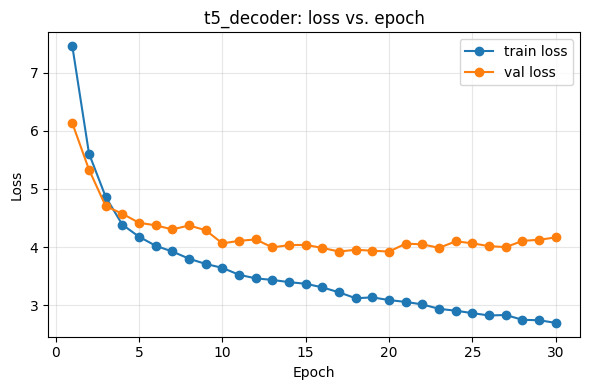

t5_decoder final_val_loss = 4.168234777450562


In [15]:
t5_tokenizer = AutoTokenizer.from_pretrained(CONFIG["t5_name"])
t5_model = ChartTableGenerator(CONFIG["encoder_name"], "t5", CONFIG["t5_name"])

result_t5 = train_model(t5_model, t5_tokenizer, df_train_final, df_val_internal, tag="t5_decoder")
print(result_t5["tag"], "final_val_loss =", result_t5["final_val_loss"])

## Step 6 — Experiment 2: Pix2Struct (frozen) + BART decoder

config.json:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

[bart_decoder] trainable params: 140,012,544  frozen params: 91,835,904
[bart_decoder] epoch 1/30  train_loss=6.2559  val_loss=5.3974  (23.1s)
[bart_decoder] epoch 2/30  train_loss=4.9912  val_loss=6.3800  (23.4s)
[bart_decoder] epoch 3/30  train_loss=4.7253  val_loss=5.2824  (22.6s)
[bart_decoder] epoch 4/30  train_loss=4.5778  val_loss=5.2513  (22.8s)
[bart_decoder] epoch 5/30  train_loss=4.5361  val_loss=5.3374  (23.1s)
[bart_decoder] epoch 6/30  train_loss=4.6772  val_loss=5.7747  (22.8s)
[bart_decoder] epoch 7/30  train_loss=4.7289  val_loss=5.8104  (22.8s)
[bart_decoder] epoch 8/30  train_loss=4.6677  val_loss=6.1939  (23.0s)
[bart_decoder] epoch 9/30  train_loss=4.5596  val_loss=6.3217  (22.9s)
[bart_decoder] epoch 10/30  train_loss=4.4524  val_loss=7.5230  (22.9s)
[bart_decoder] epoch 11/30  train_loss=4.3541  val_loss=7.2337  (22.9s)
[bart_decoder] epoch 12/30  train_loss=4.3083  val_loss=7.1332  (22.9s)
[bart_decoder] epoch 13/30  train_loss=4.3304  val_loss=9.8146  (22.8s)
[

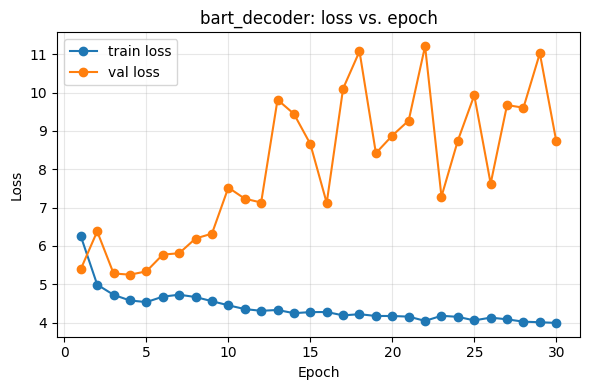

bart_decoder final_val_loss = 8.738275146484375


In [16]:
bart_tokenizer = AutoTokenizer.from_pretrained(CONFIG["bart_name"])
bart_model = ChartTableGenerator(CONFIG["encoder_name"], "bart", CONFIG["bart_name"])

result_bart = train_model(bart_model, bart_tokenizer, df_train_final, df_val_internal, tag="bart_decoder")
print(result_bart["tag"], "final_val_loss =", result_bart["final_val_loss"])

## Step 7 — Compare the two architectures on held-out test charts

In [31]:
from tqdm.auto import tqdm

def evaluate_architecture(model, tokenizer, df_eval, config=CONFIG, tag="",
                           eval_max_new_tokens=96, eval_num_beams=1, max_qa_samples=150):
    model.eval()
    rows = []
    unique_charts = df_eval.drop_duplicates("image_path")
    for _, row in tqdm(unique_charts.iterrows(), total=len(unique_charts), desc=f"[{tag}] cell accuracy"):
        gold_table = load_gold_table(row["table_path"])
        if not gold_table:
            continue
        image = Image.open(row["image_path"]).convert("RGB")
        enc = processor(images=image, return_tensors="pt", max_patches=config["max_patches"])
        out_ids = model.generate(
            flattened_patches=enc["flattened_patches"].to(DEVICE),
            attention_mask=enc["attention_mask"].to(DEVICE),
            max_new_tokens=eval_max_new_tokens, num_beams=eval_num_beams,
        )
        pred_table = delinearize_table(tokenizer.decode(out_ids[0], skip_special_tokens=True))
        mined_here = pseudo_train.get(row["image_path"], {})
        overall, mined_acc, unmined_acc = cell_accuracy(pred_table, gold_table, set(mined_here.keys()))
        rows.append({"image_path": row["image_path"], "overall_acc": overall,
                      "mined_acc": mined_acc, "unmined_acc": unmined_acc,
                      "n_gold_cells": len(gold_table), "n_pred_cells": len(pred_table)})
    cell_df = pd.DataFrame(rows)

    # cap the QA set instead of iterating every held-out human question
    held_out_human = df_eval[df_eval["source"] == "human"]
    if len(held_out_human) > max_qa_samples:
        held_out_human = held_out_human.sample(n=max_qa_samples, random_state=SEED)

    qa_rows = []
    for _, row in tqdm(held_out_human.iterrows(), total=len(held_out_human), desc=f"[{tag}] QA accuracy"):
        gold_val = clean_num(row["answer"])
        if gold_val is None:
            continue
        image = Image.open(row["image_path"]).convert("RGB")
        enc = processor(images=image, return_tensors="pt", max_patches=config["max_patches"])
        out_ids = model.generate(
            flattened_patches=enc["flattened_patches"].to(DEVICE),
            attention_mask=enc["attention_mask"].to(DEVICE),
            max_new_tokens=eval_max_new_tokens, num_beams=eval_num_beams,
        )
        pred_table = delinearize_table(tokenizer.decode(out_ids[0], skip_special_tokens=True))
        pred_ans = simple_qa_execute(row["question"], pred_table)
        correct = pred_ans is not None and abs(pred_ans - gold_val) / max(abs(gold_val), 1e-6) <= 0.05
        qa_rows.append({"correct": correct})
    qa_df = pd.DataFrame(qa_rows)

    return {
        "tag": tag,
        "mean_overall_cell_acc": cell_df["overall_acc"].dropna().mean() if len(cell_df) else None,
        "mean_mined_cell_acc":   cell_df["mined_acc"].dropna().mean()   if len(cell_df) else None,
        "mean_unmined_cell_acc": cell_df["unmined_acc"].dropna().mean() if len(cell_df) else None,
        "relaxed_qa_accuracy":   qa_df["correct"].mean() if len(qa_df) else None,
        "n_charts_evaluated":    len(cell_df),
        "n_qa_evaluated":        len(qa_df),
    }, cell_df # keep original 2-value return shape if your Step 7 unpacks two values

In [32]:
summary_t5, celldf_t5     = evaluate_architecture(t5_model,   t5_tokenizer,   df_test, tag="t5_decoder")
summary_bart, celldf_bart = evaluate_architecture(bart_model, bart_tokenizer, df_test, tag="bart_decoder")

comparison = pd.DataFrame([
    {**summary_t5,   "trainable_params": result_t5["trainable_params"],   "frozen_params": result_t5["frozen_params"],
     "final_train_loss": result_t5["final_train_loss"], "final_val_loss": result_t5["final_val_loss"]},
    {**summary_bart, "trainable_params": result_bart["trainable_params"], "frozen_params": result_bart["frozen_params"],
     "final_train_loss": result_bart["final_train_loss"], "final_val_loss": result_bart["final_val_loss"]},
])
comparison.to_csv(os.path.join(CONFIG["out_dir"], "architecture_comparison.csv"), index=False)
print(comparison.to_string(index=False))

[t5_decoder] cell accuracy:   0%|          | 0/1169 [00:00<?, ?it/s]

[t5_decoder] QA accuracy:   0%|          | 0/150 [00:00<?, ?it/s]

[bart_decoder] cell accuracy:   0%|          | 0/1169 [00:00<?, ?it/s]

[bart_decoder] QA accuracy:   0%|          | 0/150 [00:00<?, ?it/s]

         tag  mean_overall_cell_acc  mean_mined_cell_acc  mean_unmined_cell_acc  relaxed_qa_accuracy  n_charts_evaluated  n_qa_evaluated  trainable_params  frozen_params  final_train_loss  final_val_loss
  t5_decoder                    0.0                  NaN                    0.0             0.009709                1166             103          60901376       91835904          2.700514        4.168235
bart_decoder                    0.0                  NaN                    0.0             0.000000                1166             103         140012544       91835904          3.993617        8.738275


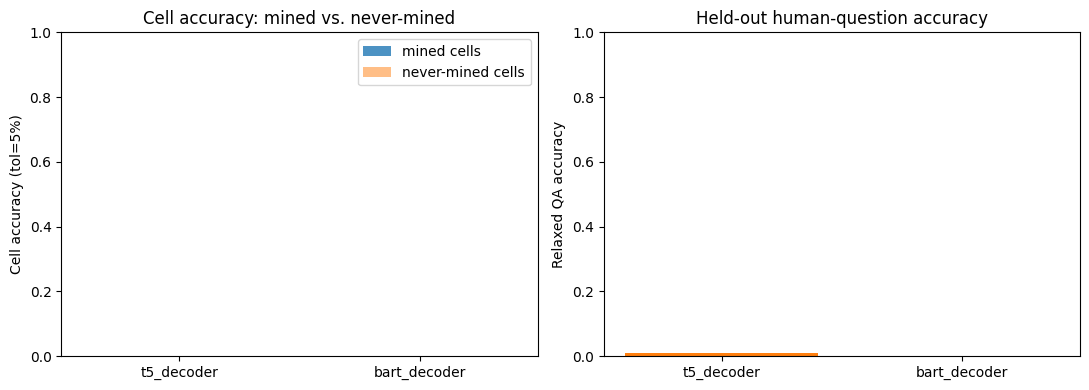

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(comparison["tag"], comparison["mean_mined_cell_acc"].fillna(0), label="mined cells", alpha=0.8)
axes[0].bar(comparison["tag"], comparison["mean_unmined_cell_acc"].fillna(0), label="never-mined cells", alpha=0.5)
axes[0].set_ylabel("Cell accuracy (tol=5%)"); axes[0].set_title("Cell accuracy: mined vs. never-mined")
axes[0].legend(); axes[0].set_ylim(0, 1)

axes[1].bar(comparison["tag"], comparison["relaxed_qa_accuracy"].fillna(0), color="tab:orange")
axes[1].set_ylabel("Relaxed QA accuracy"); axes[1].set_title("Held-out human-question accuracy")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG["out_dir"], "architecture_comparison.png"), dpi=150)
plt.show()

In [34]:
# Final, single consolidated report file -- quote numbers from this directly in your written report.
report = {
    "config": CONFIG,
    "data_stats": {
        "train_total_qa_pairs": len(df_train),
        "train_mined_qa_pairs": int(sum(mined_flags_train)),
        "train_usable_charts": len(usable_charts),
    },
    "experiments": {
        "t5_decoder":   {k: v for k, v in result_t5.items()   if k != "history"},
        "bart_decoder": {k: v for k, v in result_bart.items() if k != "history"},
    },
    "evaluation": {
        "t5_decoder": summary_t5,
        "bart_decoder": summary_bart,
    },
}
with open(os.path.join(CONFIG["out_dir"], "experiment_report.json"), "w") as f:
    json.dump(report, f, indent=2, default=str)
print("Saved:", os.path.join(CONFIG["out_dir"], "experiment_report.json"))

Saved: /kaggle/working/experiments/experiment_report.json


## Step 8 — Qualitative examples (predicted vs. gold table, side by side)

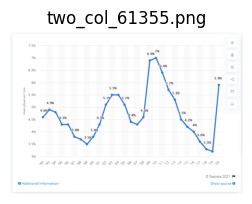

[t5_decoder] PREDICTED: {'the estimated number of men': 93.0}
[t5_decoder] GOLD:      {"'20": 5.9, "'19": 3.2, "'18": 3.3, "'17": 3.6, "'16": 4.0, "'15": 4.2, "'14": 4.5, "'13": 5.3, "'12": 5.7, "'11": 6.4, "'10": 7.0, "'09": 6.9, "'08": 4.6, "'07": 4.3, "'06": 4.4, "'05": 5.1, "'04": 5.5, "'03": 5.5, "'02": 5.1, "'01": 4.3, "'00": 3.8, "'99": 3.5, "'98": 3.7, "'97": 3.8, "'96": 4.3, "'95": 4.3, "'94": 4.8, "'93": 4.9, "'92": 4.6}
--------------------------------------------------------------------------------


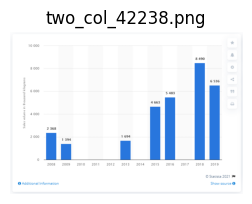

[t5_decoder] PREDICTED: {'the estimated number of men': 93.0}
[t5_decoder] GOLD:      {'2019': 6536.0, '2018': 8490.0, '2016': 5483.0, '2015': 4663.0, '2013': 1694.0, '2009': 1394.0, '2008': 2368.0}
--------------------------------------------------------------------------------


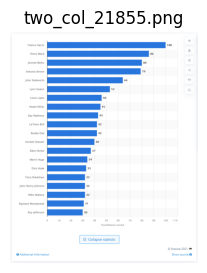

[t5_decoder] PREDICTED: {'the average of people': 78.0}
[t5_decoder] GOLD:      {'Franco Harris': 100.0, 'Hines Ward': 86.0, 'Jerome Bettis': 80.0, 'Antonio Brown': 79.0, 'John Stallworth': 64.0, 'Lynn Swann': 53.0, 'Louis Lipps': 46.0, 'Heath Miller': 45.0, 'Ray Mathews': 43.0, "Le'Veon Bell": 42.0, 'Buddy Dial': 42.0, 'Kordell Stewart': 40.0, 'Elbie Nickel': 37.0, 'Merril Hoge': 34.0, 'Dick Hoak': 33.0, 'Terry Bradshaw': 32.0, 'John Henry Johnson': 32.0, 'Mike Wallace': 32.0, 'Rashard Mendenhall': 31.0, 'Roy Jefferson': 30.0}
--------------------------------------------------------------------------------


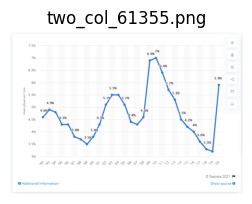

[bart_decoder] PREDICTED: {}
[bart_decoder] GOLD:      {"'20": 5.9, "'19": 3.2, "'18": 3.3, "'17": 3.6, "'16": 4.0, "'15": 4.2, "'14": 4.5, "'13": 5.3, "'12": 5.7, "'11": 6.4, "'10": 7.0, "'09": 6.9, "'08": 4.6, "'07": 4.3, "'06": 4.4, "'05": 5.1, "'04": 5.5, "'03": 5.5, "'02": 5.1, "'01": 4.3, "'00": 3.8, "'99": 3.5, "'98": 3.7, "'97": 3.8, "'96": 4.3, "'95": 4.3, "'94": 4.8, "'93": 4.9, "'92": 4.6}
--------------------------------------------------------------------------------


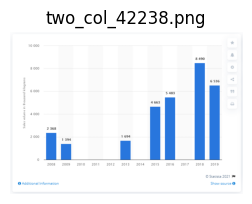

[bart_decoder] PREDICTED: {}
[bart_decoder] GOLD:      {'2019': 6536.0, '2018': 8490.0, '2016': 5483.0, '2015': 4663.0, '2013': 1694.0, '2009': 1394.0, '2008': 2368.0}
--------------------------------------------------------------------------------


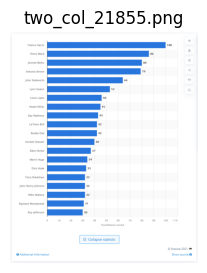

[bart_decoder] PREDICTED: {}
[bart_decoder] GOLD:      {'Franco Harris': 100.0, 'Hines Ward': 86.0, 'Jerome Bettis': 80.0, 'Antonio Brown': 79.0, 'John Stallworth': 64.0, 'Lynn Swann': 53.0, 'Louis Lipps': 46.0, 'Heath Miller': 45.0, 'Ray Mathews': 43.0, "Le'Veon Bell": 42.0, 'Buddy Dial': 42.0, 'Kordell Stewart': 40.0, 'Elbie Nickel': 37.0, 'Merril Hoge': 34.0, 'Dick Hoak': 33.0, 'Terry Bradshaw': 32.0, 'John Henry Johnson': 32.0, 'Mike Wallace': 32.0, 'Rashard Mendenhall': 31.0, 'Roy Jefferson': 30.0}
--------------------------------------------------------------------------------


In [35]:
def show_qualitative(model, tokenizer, df_eval, n=3, tag=""):
    sample = df_eval.drop_duplicates("image_path").sample(n=min(n, len(df_eval)), random_state=SEED)
    for _, row in sample.iterrows():
        gold_table = load_gold_table(row["table_path"]) or {}
        image = Image.open(row["image_path"]).convert("RGB")
        enc = processor(images=image, return_tensors="pt", max_patches=CONFIG["max_patches"])
        out_ids = model.generate(
            flattened_patches=enc["flattened_patches"].to(DEVICE),
            attention_mask=enc["attention_mask"].to(DEVICE),
            max_new_tokens=CONFIG["max_target_len"], num_beams=2,
        )
        pred_table = delinearize_table(tokenizer.decode(out_ids[0], skip_special_tokens=True))

        fig, ax = plt.subplots(figsize=(3, 3))
        ax.imshow(image); ax.axis("off"); ax.set_title(os.path.basename(row["image_path"]))
        plt.show()
        print(f"[{tag}] PREDICTED:", pred_table)
        print(f"[{tag}] GOLD:     ", gold_table)
        print("-" * 80)

show_qualitative(t5_model, t5_tokenizer, df_test, n=3, tag="t5_decoder")
show_qualitative(bart_model, bart_tokenizer, df_test, n=3, tag="bart_decoder")

## Step 9 — Inference: try your own chart image

Give this function the path to *any* chart image (does not need to be from the dataset) and it
will run the frozen encoder + your chosen trained decoder and return the predicted table as a
pandas DataFrame.

In [36]:
def predict_table(image_path="/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/png/00108924006058.png", arch="bart"):
    model, tokenizer = (t5_model, t5_tokenizer) if arch == "t5" else (bart_model, bart_tokenizer)
    model.eval()
    image = Image.open(image_path).convert("RGB")
    enc = processor(images=image, return_tensors="pt", max_patches=CONFIG["max_patches"])
    out_ids = model.generate(
        flattened_patches=enc["flattened_patches"].to(DEVICE),
        attention_mask=enc["attention_mask"].to(DEVICE),
        max_new_tokens=CONFIG["max_target_len"], num_beams=4,
    )
    text = tokenizer.decode(out_ids[0], skip_special_tokens=True)
    table = delinearize_table(text)

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(image); ax.axis("off"); ax.set_title("Input chart")
    plt.show()

    table_df = pd.DataFrame(list(table.items()), columns=["category", "predicted_value"])
    print("Raw generated text:", text)
    return table_df

# Example usage (replace with any chart image path, e.g. one you upload to /kaggle/working):
# predict_table("/kaggle/working/my_new_chart.png", arch="t5")
# predict_table("/kaggle/working/my_new_chart.png", arch="bart")

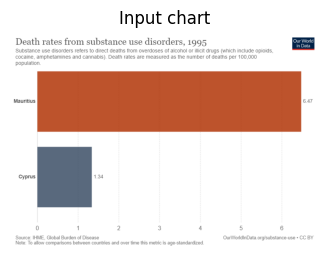

Raw generated text: thethethethe = of sum =the ofthe sumthe difference differencethe number numbertheCanadaCanadathesafetysafetytheIndiaIndiathe segment segmentthe percentage percentagethe total totalthe value valuethelargestlargestthedarkdarkthesmallsmallthe highest highesttheChinaChinathe 0 0the longest longestthe bar barthevaluevaluetheSupportSupportthe lowest lowestthe blue bluetheFindFindthe's'sthe average averagethe..the data datathe Rep ReptheWhatWhatthe between betweenthe healthcare healthcaretheOrangeOrangetheCassCassthe fat fatthe


,category,predicted_value


In [37]:
predict_table(image_path="/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/png/00108924006058.png", arch="bart")

## Where everything is saved

```
/kaggle/working/experiments/
  t5_decoder/
    loss_history.csv            <- epoch, train_loss, val_loss, seconds
    loss_curve.png
    sample_generations.json     <- what the model actually generated, per epoch
    trainable_weights.pt        <- proj + layernorm + decoder weights (encoder is frozen, not re-saved)
  bart_decoder/
    (same files)
  architecture_comparison.csv
  architecture_comparison.png
  experiment_report.json        <- single file to quote numbers from in your report
```

Download the whole `experiments/` folder from the Kaggle output panel after the run finishes.

In [38]:
import shutil
from IPython.display import FileLink, display

zip_path = shutil.make_archive(
    "/kaggle/working/experiments_backup",
    "zip",
    root_dir="/kaggle/working",
    base_dir="experiments"
)

display(FileLink("experiments_backup.zip"))

/kaggle/working/experiments_backup.zip